In [1]:
from componergy.paths import NOAA_CA_DIR, NOAA_MONTHLY_FILE
from componergy.preprocessing.crop_nclimgrid import main as crop
from componergy.preprocessing.verify_crop import find_corrupted_files
from componergy.preprocessing.aggregate_monthly import main as aggregate
crop()

loading California boundary...
California boundary ready.
found 908 raw files, 0 pending, 908 already cropped


cropping to California: 0file [00:00, ?file/s]

crop complete: 0 succeeded, 0 failed, 908 already done.


In [2]:
bad = find_corrupted_files(NOAA_CA_DIR); print('corrupted cropped files:', len(bad)); bad[:5]

corrupted cropped files: 0


[]

/mnt/Workspace/Work/componergy/data/processed/california_monthly_climate.nc already exists, skipping (pass force=True to rebuild).
{'time': 908, 'lat': 227, 'lon': 247} 1951-01 to 2026-08


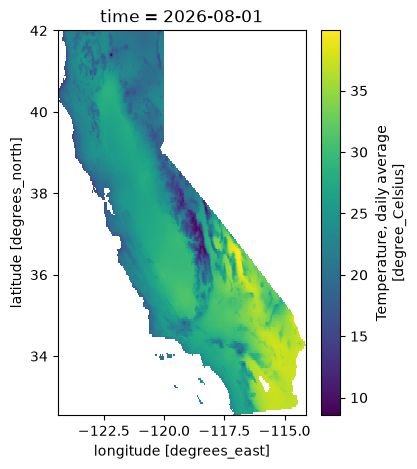

In [3]:
aggregate()
import xarray as xr
ds = xr.open_dataset(NOAA_MONTHLY_FILE)
print(dict(ds.sizes), str(ds.time.values[0])[:7], 'to', str(ds.time.values[-1])[:7])
ds['tavg'].isel(time=-1).plot(figsize=(4, 5))